In [ ]:
import json
import joblib
import pandas as pd
from pathlib import Path

# Dùng đúng artifact và metadata được Notebook 03 xuất ra.
PROJECT_DIR = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "notebooks" / "03_Model Training.ipynb").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Hãy chạy notebook trong thư mục dự án")
MODEL_PATH = PROJECT_DIR / "models" / "fraud_detection_model.joblib"
METADATA_PATH = MODEL_PATH.with_name("model_metadata.json")
model = joblib.load(MODEL_PATH)
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))

FEATURE_NAMES = metadata["features"]
THRESHOLD = float(metadata["threshold"])
if list(model.feature_names_in_) != FEATURE_NAMES:
    raise ValueError("Feature của artifact không khớp metadata")
if list(model.classes_) != [0, 1] or not 0 < THRESHOLD < 1:
    raise ValueError("Lớp dự đoán hoặc threshold không hợp lệ")

print("Đã tải mô hình:", MODEL_PATH)
print("Số đặc trưng:", len(FEATURE_NAMES))
print("Ngưỡng phân loại offline:", THRESHOLD)


In [ ]:
# Tạo một giao dịch chuyển khoản giả lập
transaction = {
    "amount": 50_000_000,
    "channel": "MobileBanking",
    "type_code": "TRANSFER",
    "hour": 2,
    "day_of_week": 1,
    "is_night_transaction": 1,
    "account_age_days": 25,
    "txn_count_1h": 5,
    "txn_count_24h": 8,
    "txn_count_7d": 10,
    "txn_count_30d": 12,
    "avg_amount_30d": 1_000_000,
    "max_amount_30d": 3_000_000,
    "amount_to_avg_ratio": 50.0,
    "failed_login_count_24h": 6,
    "successful_login_count_24h": 1,
    "failed_login_count_1h": 4,
    "time_since_last_transaction": 300.0,
    "login_failure_ratio_24h": 6 / 7
}

# Chuyển giao dịch thành DataFrame gồm 19 đặc trưng
X = pd.DataFrame([transaction])[FEATURE_NAMES]

print("Kích thước dữ liệu:", X.shape)
display(X.T)


Kích thước dữ liệu: (1, 19)


,0
amount,50000000
channel,MobileBanking
type_code,TRANSFER
hour,2
day_of_week,1
is_night_transaction,1
account_age_days,25
txn_count_1h,5
txn_count_24h,8
txn_count_7d,10


In [ ]:
# Dự đoán xác suất gian lận của giao dịch
fraud_index = list(model.classes_).index(1)
fraud_probability = model.predict_proba(X)[0, fraud_index]

# Phân loại theo ngưỡng đã chọn
prediction = "Fraud" if fraud_probability >= THRESHOLD else "Normal"

# Hiển thị kết quả
print(f"Xác suất gian lận: {fraud_probability:.2%}")
print(f"Ngưỡng phân loại: {THRESHOLD}")
print(f"Kết quả dự đoán: {prediction}")


Xác suất gian lận: 96.63%
Ngưỡng phân loại: 0.408
Kết quả dự đoán: Fraud


In [ ]:
from pathlib import Path

# Kiểm tra thư mục làm việc hiện tại
print("Thư mục hiện tại:", Path.cwd())

# Tìm các file Dataset trong dự án
for file in Path.cwd().rglob("fraud_modeling_dataset*.csv"):
    print("Tìm thấy:", file)


Thư mục hiện tại: d:\banking-fraud-detection\notebooks


In [ ]:
# 4.3 - DỰ ĐOÁN GIAN LẬN HÀNG LOẠT
import numpy as np

# Đọc dữ liệu đã chuẩn bị từ Notebook 02
DATA_PATH = PROJECT_DIR / "data" / "processed" / "fraud_modeling_dataset.csv"
df = pd.read_csv(DATA_PATH)

# Lấy đúng 19 đặc trưng đầu vào
X_batch = df[FEATURE_NAMES]

# Dự đoán xác suất gian lận
fraud_index = list(model.classes_).index(1)
probabilities = model.predict_proba(X_batch)[:, fraud_index]

# Lưu kết quả dự đoán
results = df.copy()
results["fraud_probability"] = probabilities
results["prediction"] = np.where(
    probabilities >= THRESHOLD, "Fraud", "Normal"
)

# Thống kê số lượng và tỷ lệ giao dịch gian lận
print("Tổng số giao dịch:", len(results))
print("\nSố lượng theo kết quả dự đoán:")
print(results["prediction"].value_counts())
print(f"\nTỷ lệ cảnh báo gian lận: {(results['prediction'] == 'Fraud').mean():.2%}")

# Hiển thị 5 giao dịch đầu tiên
display(results[["fraud_probability", "prediction"]].head())


In [35]:
# 4.4.1 - PHÂN TÍCH GIAO DỊCH NGHI NGỜ

# Lọc các giao dịch được mô hình cảnh báo
fraud_transactions = results[
    results["prediction"] == "Fraud"
].copy()

# Thống kê các giao dịch nghi ngờ
print("Số giao dịch nghi ngờ:", len(fraud_transactions))
print(f"Tổng số tiền: {fraud_transactions['amount'].sum():,.0f}")
print(f"Số tiền trung bình: {fraud_transactions['amount'].mean():,.0f}")
print(f"Xác suất gian lận trung bình: {fraud_transactions['fraud_probability'].mean():.2%}")

# Hiển thị 10 giao dịch có xác suất gian lận cao nhất
top_fraud = fraud_transactions.nlargest(
    10, "fraud_probability"
)

display(top_fraud[[
    "transaction_id",
    "amount",
    "channel",
    "type_code",
    "fraud_probability"
]])


Số giao dịch nghi ngờ: 2303
Tổng số tiền: 77,985,685,000
Số tiền trung bình: 33,862,651
Xác suất gian lận trung bình: 88.28%


,transaction_id,amount,channel,type_code,fraud_probability
1984,1985,81109000.0,MobileBanking,TRANSFER,0.996707
18298,18299,78743000.0,MobileBanking,TRANSFER,0.996634
27767,27768,72817000.0,MobileBanking,TRANSFER,0.996549
110,111,70559000.0,MobileBanking,TRANSFER,0.996536
15255,15256,79741000.0,ATM,TRANSFER,0.996516
17385,17386,72399000.0,InternetBanking,TRANSFER,0.996492
7686,7687,73460000.0,MobileBanking,TRANSFER,0.996484
3232,3233,81969000.0,MobileBanking,TRANSFER,0.996483
3782,3783,74702000.0,MobileBanking,TRANSFER,0.996483
2012,2013,84240000.0,MobileBanking,TRANSFER,0.996482


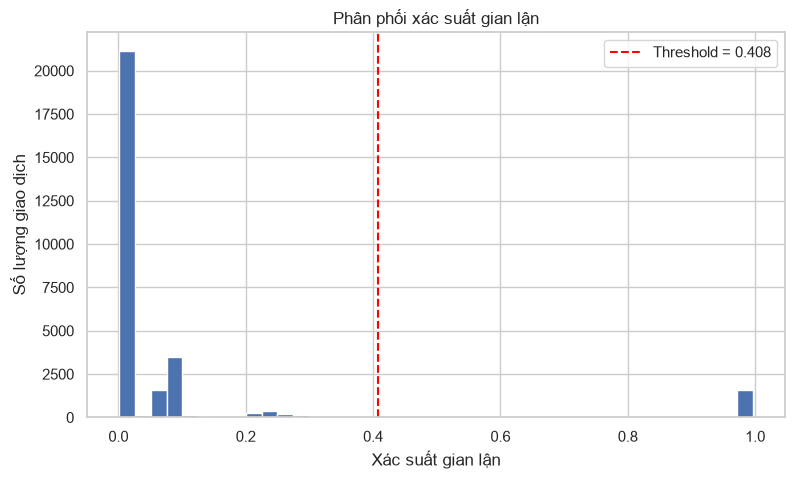

In [37]:
# 4.4.2 — Trực quan hóa kết quả dự đoán
import matplotlib.pyplot as plt

# Vẽ phân phối xác suất gian lận
plt.figure(figsize=(9, 5))

plt.hist(
    results["fraud_probability"],
    bins=40,
    edgecolor="white"
)

# Đánh dấu ngưỡng phân loại
plt.axvline(
    THRESHOLD,
    color="red",
    linestyle="--",
    label=f"Threshold = {THRESHOLD}"
)

plt.title("Phân phối xác suất gian lận")
plt.xlabel("Xác suất gian lận")
plt.ylabel("Số lượng giao dịch")
plt.legend()
plt.show()


In [38]:
# 4.5 - XUẤT KẾT QUẢ DỰ ĐOÁN
# Tạo thư mục lưu kết quả tại thư mục gốc dự án
OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Xuất toàn bộ giao dịch và kết quả dự đoán
results.to_csv(
    OUTPUT_DIR / "predictions.csv",
    index=False
)

# Xuất các giao dịch được cảnh báo gian lận
fraud_transactions.to_csv(
    OUTPUT_DIR / "fraud_transactions.csv",
    index=False
)

# Kiểm tra kết quả xuất file
print("Đã xuất dữ liệu thành công!")
print("Tổng giao dịch:", len(results))
print("Giao dịch bị cảnh báo:", len(fraud_transactions))
print("Thư mục lưu:", OUTPUT_DIR.resolve())


Đã xuất dữ liệu thành công!
Tổng giao dịch: 30000
Giao dịch bị cảnh báo: 2303
Thư mục lưu: D:\banking-fraud-detection\outputs
